In [28]:
import os, base64, json, re, time
from pathlib import Path

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine, text

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)

BASE = "https://d1yyqbluk0oz0t.cloudfront.net"

WINDOW_START   = "2026-06-01"
WINDOW_END     = "2026-10-05 23:59:59"
KNOCKOUT_START = "2026-06-28"
AS_OF          = WINDOW_END
ws_, we_ = pd.Timestamp(WINDOW_START), pd.Timestamp(WINDOW_END)
TW = f"ts BETWEEN TIMESTAMP '{WINDOW_START}' AND TIMESTAMP '{WINDOW_END}'"

CACHE = Path("wc_cache")
(CACHE / "trades").mkdir(parents=True, exist_ok=True)
(CACHE / "book").mkdir(parents=True, exist_ok=True)

con = duckdb.connect()
con.execute("INSTALL httpfs; LOAD httpfs;")
con.execute("SET TimeZone = 'UTC'")
token = base64.b64encode(f"{os.environ['PM_CF_USER']}:{os.environ['PM_CF_PASSWORD']}".encode()).decode()
con.execute(f"""
    CREATE OR REPLACE SECRET cloudfront_auth (
        TYPE http, EXTRA_HTTP_HEADERS MAP {{'Authorization': 'Basic {token}'}}
    )
""")

engine = create_engine(os.environ["PM_DB_URL"])
def q(sql):
    return pd.read_sql(text(sql), engine)

def register(name, df):
    df = df.copy()
    for c in df.columns:
        if pd.api.types.is_string_dtype(df[c]) and not pd.api.types.is_object_dtype(df[c]):
            df[c] = df[c].astype(object)
    con.execute("SELECT 1").fetchall()
    con.register("_tmp_df", df)
    con.execute(f"CREATE OR REPLACE TABLE {name} AS SELECT * FROM _tmp_df")
    con.unregister("_tmp_df")

print("duckdb", duckdb.__version__, "| pandas", pd.__version__)

duckdb 1.4.5 | pandas 2.2.2


In [29]:
LIME, WHITE, GRAY, DIM, DARKGRAY = "#bace77", "#ffffff", "#b1b1b1", "#4d5532", "#5c5c5c"

plt.style.use("dark_background")
plt.rcParams.update({
    "figure.facecolor": "black", "axes.facecolor": "black", "font.size": 13,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.edgecolor": "#3b3b3b", "axes.grid": False, "legend.frameon": False,
    "axes.prop_cycle": plt.cycler(color=[LIME, WHITE, GRAY]),
    "patch.edgecolor": "none", "patch.linewidth": 0, "legend.fontsize": 13,
})

FIGS = Path("figs"); FIGS.mkdir(exist_ok=True)
def save(name):
    plt.savefig(FIGS / f"{name}.png", dpi=200, transparent=True, bbox_inches="tight")
    plt.show()

In [30]:
WC_FILTER = "slug LIKE 'fifwc-%' OR slug LIKE '%2026-fifa-world-cup%'"

f = CACHE / "wc_markets_raw.parquet"
if f.exists():
    wcm = pd.read_parquet(f)
else:
    wcm = q(f"SELECT slug, title, event_slug, outcomes, token_ids, start_date, end_date FROM markets WHERE {WC_FILTER}")
    for c in ["outcomes", "token_ids"]:
        wcm[c] = wcm[c].map(lambda x: x if isinstance(x, str) or x is None else json.dumps(list(x)))
    wcm.to_parquet(f, index=False)

f = CACHE / "wc_resolutions_raw.parquet"
if f.exists():
    res = pd.read_parquet(f)
else:
    res = q(f"""SELECT market_slug, resolved_yes, price_at_close, resolved_at, uma_resolution_status
                FROM resolutions WHERE {WC_FILTER.replace('slug', 'market_slug')}""")
    res.to_parquet(f, index=False)

for c in ["start_date", "end_date"]:
    wcm[c] = pd.to_datetime(wcm[c], utc=True).dt.tz_localize(None)
res["resolved_at"] = pd.to_datetime(res.resolved_at, utc=True).dt.tz_localize(None)
res = res[res.resolved_at <= pd.Timestamp(AS_OF)]
assert res.market_slug.is_unique, "duplicate resolutions per market: merge would double-count"

as_list = lambda x: json.loads(x) if isinstance(x, str) else (list(x) if x is not None else [])
wcm["outcomes"]  = wcm.outcomes.map(as_list)
wcm["yes_token"] = wcm.token_ids.map(lambda x: (as_list(x) or [None])[0])

wcm = wcm.merge(res[["market_slug", "resolved_yes", "resolved_at"]], left_on="slug", right_on="market_slug", how="left")
wcm["winner_label"] = wcm.apply(
    lambda r: None if pd.isna(r.resolved_yes) or len(r.outcomes) < 2
    else (r.outcomes[0] if bool(r.resolved_yes) else r.outcomes[1]), axis=1)
wcm["kind"] = np.where(wcm.slug.str.startswith("fifwc-"), "match", "outright/other")

print(f"{len(wcm):,} World Cup markets | {wcm.winner_label.notna().sum():,} resolved (as of {AS_OF})")

18,315 World Cup markets | 4,395 resolved (as of 2026-10-05 23:59:59)


In [31]:
GAME_RE = re.compile(r"^fifwc-([a-z0-9]+)-([a-z0-9]+)-(\d{4}-\d{2}-\d{2})-?(.*)$")

def game_cat(bet, game):
    teams = game.split("-")[:2]
    if re.search(r"exact-score|correct-score", bet):                                      return "Game: exact score"
    if re.search(r"^(goals?|assists?|shots?|cards?)-|scorer|assist|anytime|player", bet): return "Game: player props"
    if re.search(r"total|spread|over|under|o-u|handicap|btts|both-teams|corner", bet):    return "Game: totals/BTTS/spread"
    if bet in ("moneyline", "draw", "team-to-advance", "advance", "winner") or bet in teams or bet in [f"{t}-win" for t in teams]:
        return "Game: result/advance"
    return "Game: other (halftime, penalty shootout, ...)"

def classify(slug):
    s = slug.lower()
    m = GAME_RE.match(s)
    if m:
        bet = m.group(4) or "moneyline"
        game = f"{m.group(1)}-{m.group(2)}-{m.group(3)}"
        return pd.Series(dict(scope="game", category=game_cat(bet, game), game_key=game, bet_type=bet))
    if re.search(r"golden-boot|top-scorer|golden-ball|golden-glove|best-player|young-player|mvp|player-of", s):
        return pd.Series(dict(scope="player", category="Tournament player award", game_key=None, bet_type=None))
    if "-win-the-2026-fifa-world-cup" in s:
        return pd.Series(dict(scope="team", category="Team to win the Cup", game_key=None, bet_type=None))
    if re.search(r"group|advance|reach|qualif|round-of|quarter|semi|final|eliminat", s):
        return pd.Series(dict(scope="team", category="Stage / group markets", game_key=None, bet_type=None))
    return pd.Series(dict(scope="other", category="Other", game_key=None, bet_type=None))

wcm = pd.concat([wcm, wcm.slug.apply(classify)], axis=1)

def tmpl_cat(r):
    s = r.slug.lower()
    if r.category == "Game: result/advance":    return "Game winner"
    if r.category == "Team to win the Cup":     return "Tournament winner"
    if r.category == "Game: player props" or re.search(r"golden-boot|top-scorer", s):
        return "Player props (top scorer, etc.)"
    if r.category == "Tournament player award": return "Awards"
    return "Other"

wcm["tmpl_category"] = wcm.apply(tmpl_cat, axis=1)
wcm["game_date"] = pd.to_datetime(wcm.game_key.str[-10:], errors="coerce")
wcm["stage"] = np.where(wcm.game_date.isna(), None,
                np.where(wcm.game_date >= pd.Timestamp(KNOCKOUT_START), "Knockout games", "Group stage games"))

life_end = wcm.resolved_at.fillna(wcm.end_date)
wcm["active_in_window"]   = (wcm.start_date <= we_) & (life_end >= ws_)
wcm["created_in_window"]  = wcm.start_date.between(ws_, we_)
wcm["resolved_in_window"] = wcm.resolved_at.between(ws_, we_)

meta_cols = ["slug", "title", "event_slug", "kind", "scope", "category", "tmpl_category", "stage", "game_key",
             "game_date", "bet_type", "start_date", "end_date", "resolved_at", "winner_label", "yes_token"]
register("wc_meta", wcm[meta_cols])
register("wc_tokens", wcm[wcm.yes_token.notna()][["slug", "yes_token"]])

print(wcm.category.value_counts(), "\n")
print(wcm.tmpl_category.value_counts(), "\n")
print(wcm.stage.value_counts(dropna=False))

category
Game: player props                               10540
Game: totals/BTTS/spread                          3728
Game: exact score                                 1241
Game: other (halftime, penalty shootout, ...)      971
Other                                              804
Stage / group markets                              683
Game: result/advance                               219
Tournament player award                             75
Team to win the Cup                                 54
Name: count, dtype: int64 

tmpl_category
Player props (top scorer, etc.)    10543
Other                               7427
Game winner                          219
Awards                                72
Tournament winner                     54
Name: count, dtype: int64 

stage
Group stage games    16466
None                  1616
Knockout games         233
Name: count, dtype: int64


In [32]:
TRADE_DAYS = pd.date_range(WINDOW_START, WINDOW_END[:10]).strftime("%Y-%m-%d").tolist()
KNOWN_MISSING_TRADE_DAYS = set()

def cache_query(sql, out, tries=3):
    if out.exists():
        return None
    tmp = out.with_name(out.stem + ".partial")
    err = None
    for i in range(tries):
        try:
            con.execute(f"COPY ({sql}) TO '{tmp.as_posix()}' (FORMAT parquet)")
            os.replace(tmp, out)
            return None
        except Exception as e:
            err = str(e)[:150]
            time.sleep(3 * (i + 1))
    if tmp.exists():
        tmp.unlink()
    return err

failed = {}
for d in TRADE_DAYS:
    sql = f"""
        SELECT t.wallet, t.market, CAST(CAST(t."time" AS TIMESTAMPTZ) AS TIMESTAMP) AS ts,
               t.side, t.outcome, t.price, t.size, t.dollars
        FROM read_parquet('{BASE}/wallet_trades/trades-{d}.parquet') t
        WHERE t.market IN (SELECT slug FROM wc_meta)
    """
    err = cache_query(sql, CACHE / "trades" / f"trades-{d}.parquet")
    if err and d not in KNOWN_MISSING_TRADE_DAYS:
        failed[d] = err
        print(d, "FAILED:", err)

if failed:
    raise RuntimeError(f"{len(failed)} trade day(s) failed to download: {sorted(failed)}. "
                       "Re-run this cell (finished days are cached). Numbers will be wrong if you skip them.")

trade_files = [(CACHE / "trades" / f"trades-{d}.parquet").as_posix() for d in TRADE_DAYS
               if (CACHE / "trades" / f"trades-{d}.parquet").exists()]
file_list = ", ".join(f"'{p}'" for p in trade_files)

con.execute(f"""
    CREATE OR REPLACE VIEW wc_trades AS
    SELECT t.*, m.kind, m.event_slug, m.end_date,
           (t.outcome = m.winner_label) AS bet_on_winner,
           epoch(m.resolved_at - t.ts) / 3600.0 AS hrs_to_resolve
    FROM read_parquet([{file_list}]) t
    JOIN wc_meta m ON m.slug = t.market
""")
con.execute("CREATE OR REPLACE VIEW wc_resolved_trades AS SELECT * FROM wc_trades WHERE bet_on_winner IS NOT NULL")

con.execute("""
    SELECT COUNT(*) AS fills, COUNT(DISTINCT wallet) AS wallets, COUNT(DISTINCT market) AS markets,
           SUM(dollars) AS usd, MIN(ts) AS first_ts, MAX(ts) AS last_ts
    FROM wc_trades
""").df()

,fills,wallets,markets,usd,first_ts,last_ts
0,9428974,330181,15925,1.723687e+09,2026-06-01 00:00:01,2026-07-20 02:40:51


In [33]:
SNAP_HOURS = [18]
SNAP_LAST  = str(min(we_, wcm.resolved_at.max()).date())
KNOWN_MISSING_SNAPS = {f"2026-06-{d}T18" for d in (16, 17, 18, 19)}
print("snapshots from", WINDOW_START, "to", SNAP_LAST)

snap_hours = [f"{d}T{h:02d}" for d in pd.date_range(WINDOW_START, SNAP_LAST).strftime("%Y-%m-%d") for h in SNAP_HOURS]
failed = {}
for hour in snap_hours:
    if hour in KNOWN_MISSING_SNAPS:
        continue
    url = f"{BASE}/snap-{hour}.parquet"
    sql = f"""
        WITH s AS (
            SELECT asset_id, ts_ms, bids, asks,
                   bids[1].price AS best_bid, asks[1].price AS best_ask,
                   bids[1].size  AS best_bid_size, asks[1].size AS best_ask_size,
                   len(bids) AS n_bid_levels, len(asks) AS n_ask_levels
            FROM read_parquet('{url}')
            WHERE asset_id IN (SELECT yes_token FROM wc_tokens)
        ),
        b AS (SELECT asset_id, SUM(lvl.size) AS bid_depth_5c
              FROM (SELECT asset_id, best_bid, unnest(bids) AS lvl FROM s)
              WHERE lvl.price >= best_bid - 0.05 GROUP BY asset_id),
        a AS (SELECT asset_id, SUM(lvl.size) AS ask_depth_5c
              FROM (SELECT asset_id, best_ask, unnest(asks) AS lvl FROM s)
              WHERE lvl.price <= best_ask + 0.05 GROUP BY asset_id)
        SELECT s.asset_id, CAST(to_timestamp(s.ts_ms / 1000.0) AS TIMESTAMP) AS ts,
               s.best_bid, s.best_ask, s.best_bid_size, s.best_ask_size, s.n_bid_levels, s.n_ask_levels,
               b.bid_depth_5c, a.ask_depth_5c
        FROM s LEFT JOIN b ON b.asset_id = s.asset_id LEFT JOIN a ON a.asset_id = s.asset_id
    """
    err = cache_query(sql, CACHE / "book" / f"snap-{hour}.parquet")
    if err:
        failed[hour] = err
        print(hour, "FAILED:", err)

if failed:
    raise RuntimeError(f"{len(failed)} snapshot(s) failed: {sorted(failed)}. Re-run this cell.")

book_files = ", ".join(f"'{p.as_posix()}'" for p in sorted((CACHE / "book").glob("snap-*.parquet")))
con.execute(f"CREATE OR REPLACE VIEW wc_book AS SELECT * FROM read_parquet([{book_files}])")
print(con.execute("SELECT COUNT(*) FROM wc_book").fetchone()[0], "snapshot rows")

snapshots from 2026-06-01 to 2026-07-20
108816 snapshot rows


In [34]:
vol_by_mkt = con.execute(f"""
    SELECT market AS slug, SUM(dollars) AS usd, COUNT(*) AS trades
    FROM wc_trades WHERE {TW} GROUP BY market
""").df()
traded = set(vol_by_mkt.slug)

ACTIVE_DEFINITION = "overlap"
act = wcm[wcm.slug.isin(traded)] if ACTIVE_DEFINITION == "traded" else wcm[wcm.active_in_window]
cr  = wcm[wcm.created_in_window]
dn  = wcm[wcm.resolved_in_window]
len_days = ((cr.resolved_at - cr.start_date).dt.total_seconds() / 86400).dropna()

tableA1 = pd.DataFrame([
    ["Markets active in window",     len(act), f"definition: {ACTIVE_DEFINITION}. With >=1 trade in window = {len(traded):,}; "
                                               f"life overlaps window = {int(wcm.active_in_window.sum()):,}; all World Cup markets = {len(wcm):,}"],
    ["Markets created in window",    len(cr),  "start_date (scheduled open) inside the window"],
    ["Markets resolved in window",   len(dn),  "resolved_at inside the window"],
    ["Market length, median (days)", round(len_days.median(), 2), f"only markets created in window AND resolved (n={len(len_days):,}); resolved_at - start_date"],
    ["Market length, mean (days)",   round(len_days.mean(), 2),   "mean far above median = a few very long-lived markets"],
], columns=["Metric", "Value", "Notes"])

cm = act.merge(vol_by_mkt, on="slug", how="left").fillna({"usd": 0, "trades": 0})
order = ["Game winner", "Tournament winner", "Player props (top scorer, etc.)", "Awards", "Other"]
mix = cm.groupby("tmpl_category").agg(markets=("slug", "count"), usd=("usd", "sum")).reindex(order).fillna(0)
stage = (cm[cm.stage.notna()].groupby("stage").agg(markets=("slug", "count"), usd=("usd", "sum"))
           .reindex(["Group stage games", "Knockout games"]).fillna(0))
mix = pd.concat([mix, stage])
mix["% of markets"] = mix.markets / len(cm)
mix["% of volume"]  = mix.usd / cm.usd.sum()
tableA2 = mix.rename(columns={"markets": "# markets", "usd": "Volume (USD)"}).reset_index(names="World Cup category")

print("Group/Knockout rows are a different cut (all bet types on those games), so they overlap the rows above.")
with pd.option_context("display.max_colwidth", None):
    display(tableA1)
display(tableA2.round(3))

other = (cm[cm.tmpl_category == "Other"].groupby("category")
           .agg(markets=("slug", "count"), usd=("usd", "sum")).sort_values("usd", ascending=False))
other["% of all volume"] = other.usd / cm.usd.sum()
print("What's inside 'Other':")
display(other.round(3))

Group/Knockout rows are a different cut (all bet types on those games), so they overlap the rows above.


,Metric,Value,Notes
0,Markets active in window,18237.00,"definition: overlap. With >=1 trade in window = 15,925; life overlaps window = 18,237; all World Cup markets = 18,315"
1,Markets created in window,15164.00,start_date (scheduled open) inside the window
2,Markets resolved in window,4395.00,resolved_at inside the window
3,"Market length, median (days)",4.02,"only markets created in window AND resolved (n=2,234); resolved_at - start_date"
4,"Market length, mean (days)",7.50,mean far above median = a few very long-lived markets


,World Cup category,# markets,Volume (USD),% of markets,% of volume
0,Game winner,219,8.365786e+08,0.012,0.487
1,Tournament winner,48,2.379793e+08,0.003,0.139
2,"Player props (top scorer, etc.)",10540,4.346293e+06,0.578,0.003
3,Awards,60,1.169053e+07,0.003,0.007
4,Other,7370,6.266538e+08,0.404,0.365
5,Group stage games,16466,1.378345e+09,0.903,0.803
6,Knockout games,233,3.948866e+07,0.013,0.023


What's inside 'Other':


,markets,usd,% of all volume
category,,,
Game: totals/BTTS/spread,3728,4.951233e+08,0.288
Game: exact score,1241,5.756287e+07,0.034
Stage / group markets,634,2.585386e+07,0.015
"Game: other (halftime, penalty shootout, ...)",971,2.422276e+07,0.014
Other,796,2.389102e+07,0.014


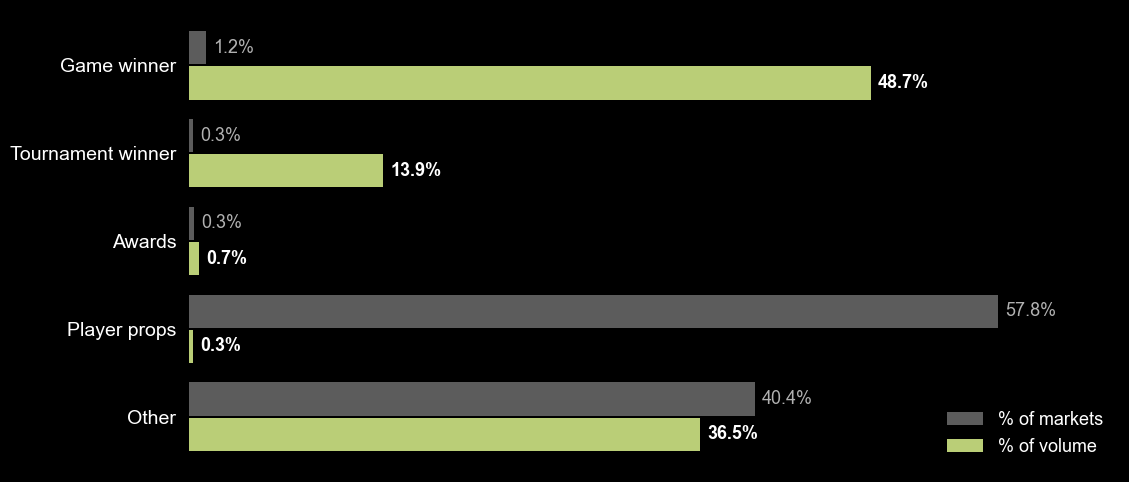

In [35]:
rows   = ["Game winner", "Tournament winner", "Awards", "Player props (top scorer, etc.)", "Other"]
names  = ["Game winner", "Tournament winner", "Awards", "Player props", "Other"]
t = tableA2.set_index("World Cup category").loc[rows]
y = np.arange(len(rows))[::-1]

fig, ax = plt.subplots(figsize=(12, 6))
ax.barh(y + 0.2, t["% of markets"], 0.38, color=DARKGRAY, label="% of markets")
ax.barh(y - 0.2, t["% of volume"],  0.38, color=LIME,     label="% of volume")
for yi, m, v in zip(y, t["% of markets"], t["% of volume"]):
    ax.text(m + 0.005, yi + 0.2, f"{m:.1%}", va="center", color=GRAY)
    ax.text(v + 0.005, yi - 0.2, f"{v:.1%}", va="center", color=WHITE, fontweight="bold")
ax.set_yticks(y); ax.set_yticklabels(names, fontsize=14)
ax.set_xticks([]); ax.tick_params(left=False); ax.spines["bottom"].set_visible(False)
ax.set_xlim(0, max(t["% of markets"].max(), t["% of volume"].max()) * 1.15)
ax.legend(loc="lower right")
save("03_category_mix")

In [36]:
tot = con.execute(f"""
    SELECT COUNT(*) AS trades, SUM(dollars) AS usd, AVG(dollars) AS avg_usd, MEDIAN(dollars) AS med_usd
    FROM wc_trades WHERE {TW}
""").df().iloc[0]
v = np.sort(vol_by_mkt.usd.values)[::-1]
k = max(1, int(len(v) * 0.01))
top1_share = v[:k].sum() / v.sum()

tableB1 = pd.DataFrame([
    ["Total volume (USD)",                   round(tot.usd, 0),     "sum of fills inside the window"],
    ["Total trades",                         int(tot.trades),       "one row per fill"],
    ["Average trade size (USD)",             round(tot.avg_usd, 2), ""],
    ["Median trade size (USD)",              round(tot.med_usd, 2), ""],
    ["Share of volume in top 1% of markets", round(top1_share, 4),  f"top {k:,} of {len(v):,} markets that traded"],
], columns=["Metric", "Value", "Notes"])

order = ["More than 7 days", "1-7 days", "6-24 hours", "1-6 hours", "Last hour", "In-play (after kickoff)"]
ko = con.execute(f"""
    SELECT CASE WHEN t.ts >= m.end_date THEN 'In-play (after kickoff)'
                WHEN epoch(m.end_date - t.ts) / 3600.0 < 1   THEN 'Last hour'
                WHEN epoch(m.end_date - t.ts) / 3600.0 < 6   THEN '1-6 hours'
                WHEN epoch(m.end_date - t.ts) / 3600.0 < 24  THEN '6-24 hours'
                WHEN epoch(m.end_date - t.ts) / 3600.0 < 168 THEN '1-7 days'
                ELSE 'More than 7 days' END AS bucket,
           SUM(t.dollars) AS usd
    FROM wc_trades t JOIN wc_meta m ON m.slug = t.market
    WHERE m.scope = 'game' AND t.{TW}
    GROUP BY 1
""").df().set_index("bucket").reindex(order).fillna(0)
ko["% of game volume"] = ko.usd / ko.usd.sum()
tableB2 = ko.rename(columns={"usd": "Volume (USD)"}).reset_index(names="Time before kickoff")

top10 = vol_by_mkt.sort_values(["usd", "slug"], ascending=[False, True]).head(10).reset_index(drop=True)
top10.insert(0, "Rank", range(1, len(top10) + 1))
tableB3 = top10.rename(columns={"slug": "Slug", "usd": "Volume (USD)", "trades": "Trades"})

display(tableB1); display(tableB2.round(3))
with pd.option_context("display.max_colwidth", None):
    display(tableB3)

,Metric,Value,Notes
0,Total volume (USD),1.723687e+09,sum of fills inside the window
1,Total trades,9.428974e+06,one row per fill
2,Average trade size (USD),1.828100e+02,
3,Median trade size (USD),9.700000e+00,
4,Share of volume in top 1% of markets,5.985000e-01,"top 159 of 15,925 markets that traded"


,Time before kickoff,Volume (USD),% of game volume
0,More than 7 days,2.551826e+06,0.002
1,1-7 days,3.676482e+07,0.026
2,6-24 hours,1.347076e+08,0.095
3,1-6 hours,1.953473e+08,0.138
4,Last hour,3.846410e+08,0.271
5,In-play (after kickoff),6.638213e+08,0.468


,Rank,Slug,Volume (USD),Trades
0,1,will-spain-win-the-2026-fifa-world-cup-963,4.220559e+07,134744
1,2,will-argentina-win-the-2026-fifa-world-cup-245,3.867466e+07,154421
2,3,will-france-win-the-2026-fifa-world-cup-924,2.801467e+07,152157
3,4,fifwc-esp-arg-2026-07-19-team-to-advance,2.248657e+07,67838
4,5,fifwc-bel-egy-2026-06-15-bel,1.844633e+07,31056
5,6,fifwc-tur-usa-2026-06-25-usa,1.719078e+07,57366
6,7,will-congo-dr-win-the-2026-fifa-world-cup,1.638311e+07,10255
7,8,fifwc-ger-civ-2026-06-20-ger,1.622328e+07,56367
8,9,fifwc-usa-par-2026-06-12-usa,1.561225e+07,52047
9,10,fifwc-jpn-swe-2026-06-25-jpn,1.511942e+07,34107


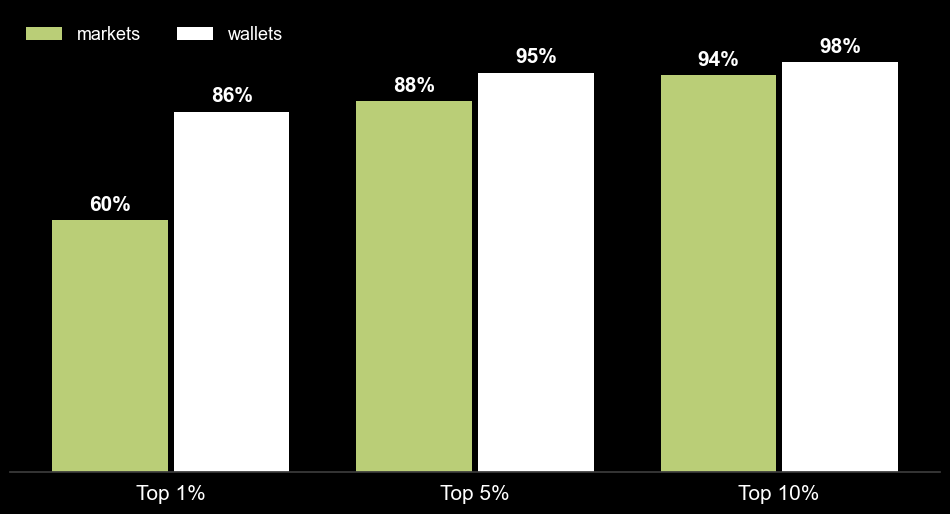

In [37]:
mkt = np.sort(vol_by_mkt.usd.values)[::-1]
wal = con.execute(f"SELECT SUM(dollars) AS usd FROM wc_trades WHERE {TW} GROUP BY wallet").df().usd.sort_values(ascending=False).values
top = lambda arr, p: arr[: max(1, int(len(arr) * p))].sum() / arr.sum()
levels = [0.01, 0.05, 0.10]
x = np.arange(3)

fig, ax = plt.subplots(figsize=(12, 6))
b1 = ax.bar(x - 0.2, [top(mkt, p) for p in levels], 0.38, color=LIME,  label="markets")
b2 = ax.bar(x + 0.2, [top(wal, p) for p in levels], 0.38, color=WHITE, label="wallets")
ax.bar_label(b1, fmt="{:.0%}", padding=4, fontsize=15, fontweight="bold")
ax.bar_label(b2, fmt="{:.0%}", padding=4, fontsize=15, fontweight="bold")
ax.set_xticks(x); ax.set_xticklabels(["Top 1%", "Top 5%", "Top 10%"], fontsize=15)
ax.set_yticks([]); ax.set_ylim(0, 1.1); ax.tick_params(bottom=False)
ax.legend(loc="upper left", ncol=2)
save("04_concentration")

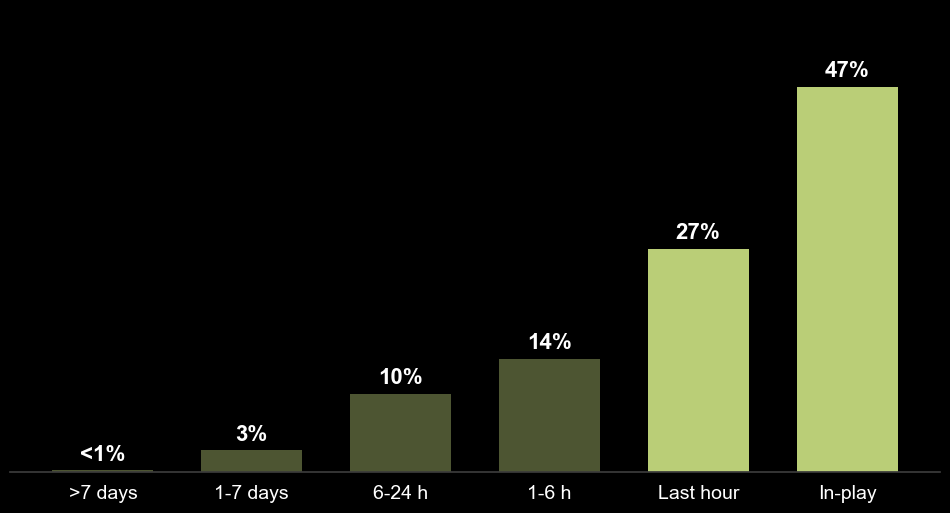

In [38]:
labels = [">7 days", "1-7 days", "6-24 h", "1-6 h", "Last hour", "In-play"]
share  = tableB2["% of game volume"].values
colors = [DIM, DIM, DIM, DIM, LIME, LIME]

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.bar(labels, share, 0.68, color=colors)
ax.bar_label(bars, labels=[("<1%" if s < 0.005 else f"{s:.0%}") for s in share],
             padding=4, fontsize=16, fontweight="bold")
ax.set_yticks([]); ax.set_ylim(0, share.max() * 1.2); ax.tick_params(bottom=False, labelsize=14)
save("05_kickoff_timing")

In [39]:
months = pd.period_range(WINDOW_START[:7], WINDOW_END[:7], freq="M")
tm = con.execute(f"""
    SELECT date_trunc('month', ts) AS month, COUNT(*) AS trades, SUM(dollars) AS usd, COUNT(DISTINCT wallet) AS traders
    FROM wc_trades WHERE {TW} GROUP BY 1
""").df()
tm["month"] = pd.to_datetime(tm.month).dt.to_period("M")
tm = tm.set_index("month")

tableB4 = pd.DataFrame(index=months)
tableB4["Markets created"]  = cr.start_date.dt.to_period("M").value_counts().reindex(months).fillna(0).astype(int)
tableB4["Markets resolved"] = dn.resolved_at.dt.to_period("M").value_counts().reindex(months).fillna(0).astype(int)
tableB4["Trades"]           = tm.trades.reindex(months).fillna(0).astype(int)
tableB4["Volume (USD)"]     = tm.usd.reindex(months).fillna(0).round(0)
tableB4["Unique traders"]   = tm.traders.reindex(months).fillna(0).astype(int)
tableB4.index = [("Oct 1-5 2026" if m.strftime("%b %Y") == "Oct 2026" else m.strftime("%b %Y")) for m in months]
tableB4 = tableB4.reset_index(names="Month")
print("Unique traders are distinct within each month, so the column does not add up to the total.")
tableB4

Unique traders are distinct within each month, so the column does not add up to the total.


,Month,Markets created,Markets resolved,Trades,Volume (USD),Unique traders
0,Jun 2026,14944,4108,8438113,1.525086e+09,267820
1,Jul 2026,220,287,990861,1.986007e+08,136795
2,Aug 2026,0,0,0,0.000000e+00,0
3,Sep 2026,0,0,0,0.000000e+00,0
4,Oct 1-5 2026,0,0,0,0.000000e+00,0


In [40]:
labels = ["More than 30 days", "8-30 days", "2-7 days", "1-2 days", "Last 24 hours"]
edges  = [0, 24, 48, 168, 720, np.inf]

live["hrs_to_res"] = (live.resolved_at - live.ts).dt.total_seconds() / 3600
lv = live[live.hrs_to_res >= 0].copy()
lv["bucket"] = pd.cut(lv.hrs_to_res, bins=edges, labels=labels[::-1], right=False)
spread_by = lv.groupby("bucket", observed=False).spread.median().reindex(labels)

vb = con.execute(f"""
    SELECT CASE WHEN hrs_to_resolve < 24  THEN 'Last 24 hours'
                WHEN hrs_to_resolve < 48  THEN '1-2 days'
                WHEN hrs_to_resolve < 168 THEN '2-7 days'
                WHEN hrs_to_resolve < 720 THEN '8-30 days'
                ELSE 'More than 30 days' END AS bucket, SUM(dollars) AS usd
    FROM wc_trades WHERE hrs_to_resolve >= 0 AND {TW} GROUP BY 1
""").df().set_index("bucket").reindex(labels).fillna(0)

tableCD = pd.DataFrame({"Time until resolution": labels, "Median spread": spread_by.values.round(4),
                        "Volume (USD)": vb.usd.round(0).values})
tableCD["% of volume"] = (vb.usd / vb.usd.sum()).values
late = con.execute(f"SELECT SUM(dollars) FROM wc_trades WHERE hrs_to_resolve < 0 AND {TW}").fetchone()[0] or 0
print(f"Resolved markets only. Fills after the recorded resolution time (excluded): ${late:,.0f}")
tableCD.round(3)

Resolved markets only. Fills after the recorded resolution time (excluded): $239,967


,Time until resolution,Median spread,Volume (USD),% of volume
0,More than 30 days,0.01,2.201020e+07,0.016
1,8-30 days,0.01,1.270031e+08,0.093
2,2-7 days,0.01,7.074002e+07,0.052
3,1-2 days,0.01,3.058537e+07,0.022
4,Last 24 hours,0.01,1.116515e+09,0.817


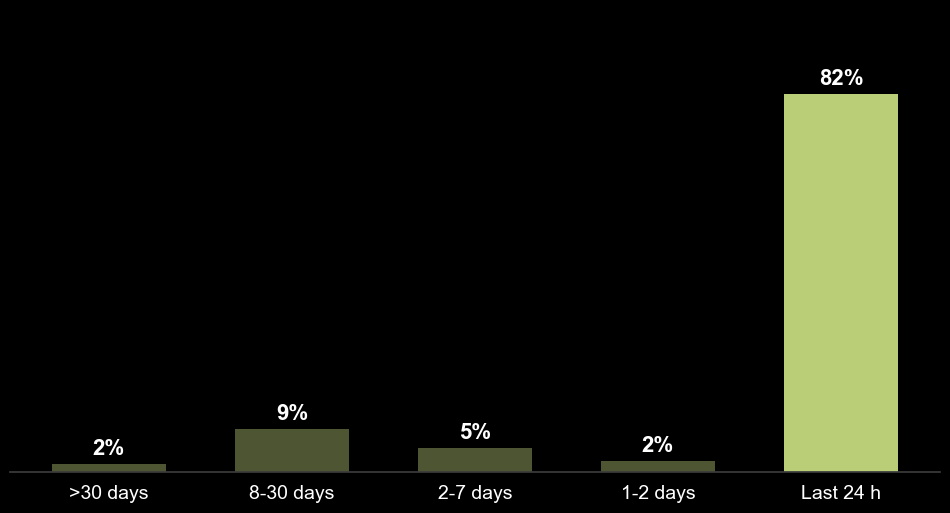

In [41]:
labels = [">30 days", "8-30 days", "2-7 days", "1-2 days", "Last 24 h"]
share  = tableCD["% of volume"].values

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.bar(labels, share, 0.62, color=[DIM, DIM, DIM, DIM, LIME])
ax.bar_label(bars, fmt="{:.0%}", padding=4, fontsize=16, fontweight="bold")
ax.set_yticks([]); ax.set_ylim(0, 1); ax.tick_params(bottom=False, labelsize=14)
save("06_time_to_resolution")

In [42]:
REF = {
    "World Cup markets":            (len(wcm),                 18315),
    "Markets active in window":     (len(act),                 18237),
    "Markets created in window":    (len(cr),                  15164),
    "Markets resolved in window":   (len(dn),                  4395),
    "Market length median (days)":  (len_days.median(),        4.02),
    "Market length mean (days)":    (len_days.mean(),          7.50),
    "Markets with >=1 trade":       (len(traded),              15925),
    "Total volume (USD)":           (tot.usd,                  1.723687e9),
    "Total trades":                 (int(tot.trades),          9428974),
    "Average trade size (USD)":     (tot.avg_usd,              182.81),
    "Median trade size (USD)":      (tot.med_usd,              9.70),
    "Top 1% market share":          (top1_share,               0.5985),
    "In-play share of game volume": (ko.loc["In-play (after kickoff)", "% of game volume"], 0.468),
    "Usable book snapshots":        (len(live),                22673),
    "Median spread":                (live.spread.median(),     0.02),
    "Mean spread":                  (live.spread.mean(),       0.0517),
    "Spread vs volume (Spearman)":  (rho,                      -0.637),
    "Last-24h share of volume":     (tableCD["% of volume"].iloc[-1], 0.817),
}
chk = pd.DataFrame([(k, a, b) for k, (a, b) in REF.items()], columns=["metric", "yours", "reference"])
chk["status"] = np.where(np.isclose(chk.yours.astype(float), chk.reference.astype(float), rtol=2e-3, atol=0.005), "ok", "DIFF")
print("All match." if (chk.status == "ok").all() else f"{(chk.status != 'ok').sum()} metric(s) differ:")
chk

All match.


,metric,yours,reference,status
0,World Cup markets,1.831500e+04,1.831500e+04,ok
1,Markets active in window,1.823700e+04,1.823700e+04,ok
2,Markets created in window,1.516400e+04,1.516400e+04,ok
3,Markets resolved in window,4.395000e+03,4.395000e+03,ok
4,Market length median (days),4.021942e+00,4.020000e+00,ok
5,Market length mean (days),7.499616e+00,7.500000e+00,ok
6,Markets with >=1 trade,1.592500e+04,1.592500e+04,ok
7,Total volume (USD),1.723687e+09,1.723687e+09,ok
8,Total trades,9.428974e+06,9.428974e+06,ok
9,Average trade size (USD),1.828075e+02,1.828100e+02,ok


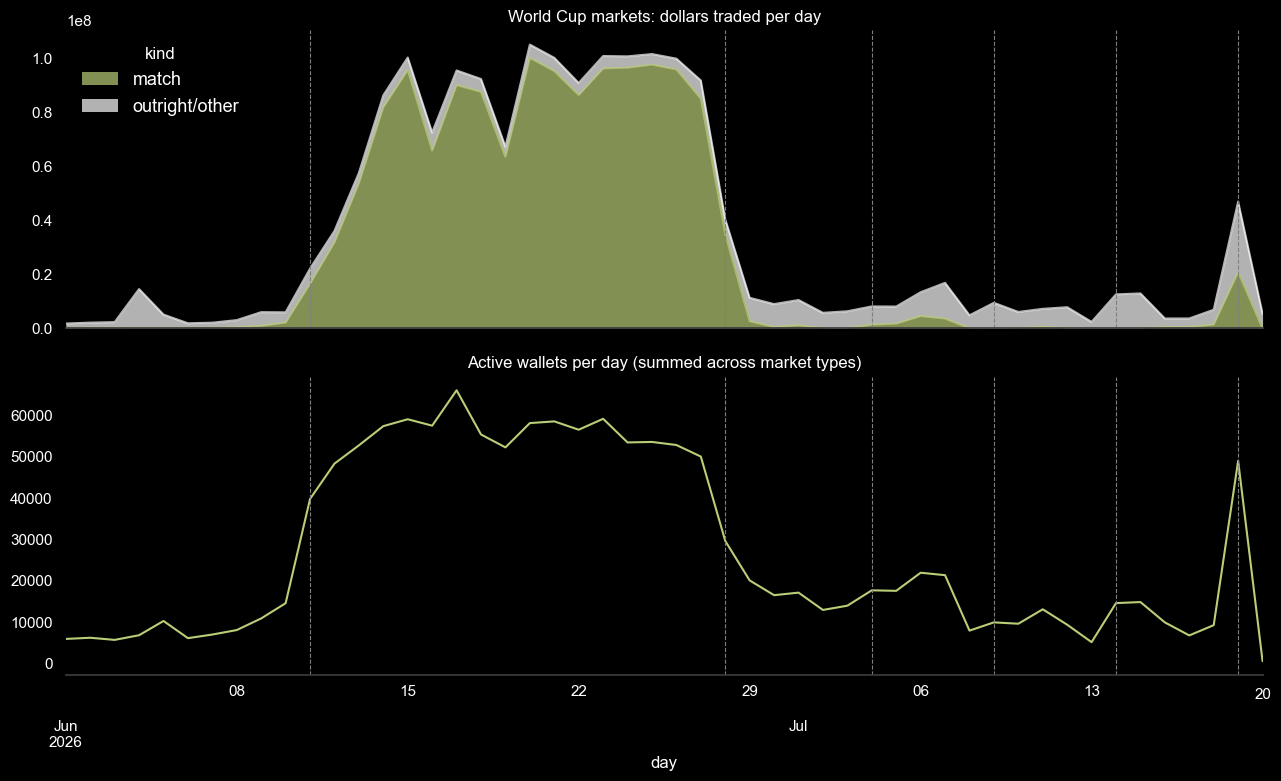

In [43]:
daily = con.execute("""
    SELECT CAST(ts AS DATE) AS day, kind, COUNT(*) AS fills, COUNT(DISTINCT wallet) AS wallets, SUM(dollars) AS usd
    FROM wc_trades GROUP BY 1, 2 ORDER BY 1, 2
""").df()
daily["day"] = pd.to_datetime(daily.day)
daily = daily[daily.day <= "2026-07-25"]

milestones = {"Kickoff": "2026-06-11", "Round of 32": "2026-06-28", "Round of 16": "2026-07-04",
              "Quarterfinals": "2026-07-09", "Semifinals": "2026-07-14", "Final": "2026-07-19"}

fig, ax = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
daily.pivot(index="day", columns="kind", values="usd").fillna(0).plot.area(ax=ax[0], alpha=0.7)
ax[0].set_title("World Cup markets: dollars traded per day")
daily.groupby("day").wallets.sum().plot(ax=ax[1])
ax[1].set_title("Active wallets per day (summed across market types)")
for a in ax:
    for name, dte in milestones.items():
        a.axvline(pd.Timestamp(dte), ls="--", color="gray", lw=0.8)
plt.tight_layout(); save("08_daily_volume")

In [44]:
con.execute("""
    SELECT CAST(end_date AS DATE) AS day, COUNT(*) AS match_markets
    FROM wc_meta WHERE kind = 'match' GROUP BY 1 ORDER BY 1
""").df()

,day,match_markets
0,2026-06-11,190
1,2026-06-12,625
2,2026-06-13,1400
3,2026-06-14,2323
4,2026-06-15,1848
5,2026-06-16,1014
6,2026-06-17,1871
7,2026-06-18,1303
8,2026-06-19,938
9,2026-06-20,1150
